<a href="https://colab.research.google.com/github/ANJARRIZANDI/simuteh-2330511035/blob/main/notebook/B2_citra_warna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
%cd /content/simuteh-2330511035/notebook

/content/simuteh-2330511035/notebook


In [7]:
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../src")

from utils_cv import baca, tampil, kontras_bercak

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("utils_cv berhasil diimpor!")

OpenCV: 5.0.0
NumPy: 2.1.3
utils_cv berhasil diimpor!


KB kanal B   : 2.01
KB kanal G   : 2.14
KB kanal R   : 12.73
KB kanal Gray: 6.15
KB kanal H   : 9.52
KB kanal S   : 0.51
KB kanal V   : 4.24


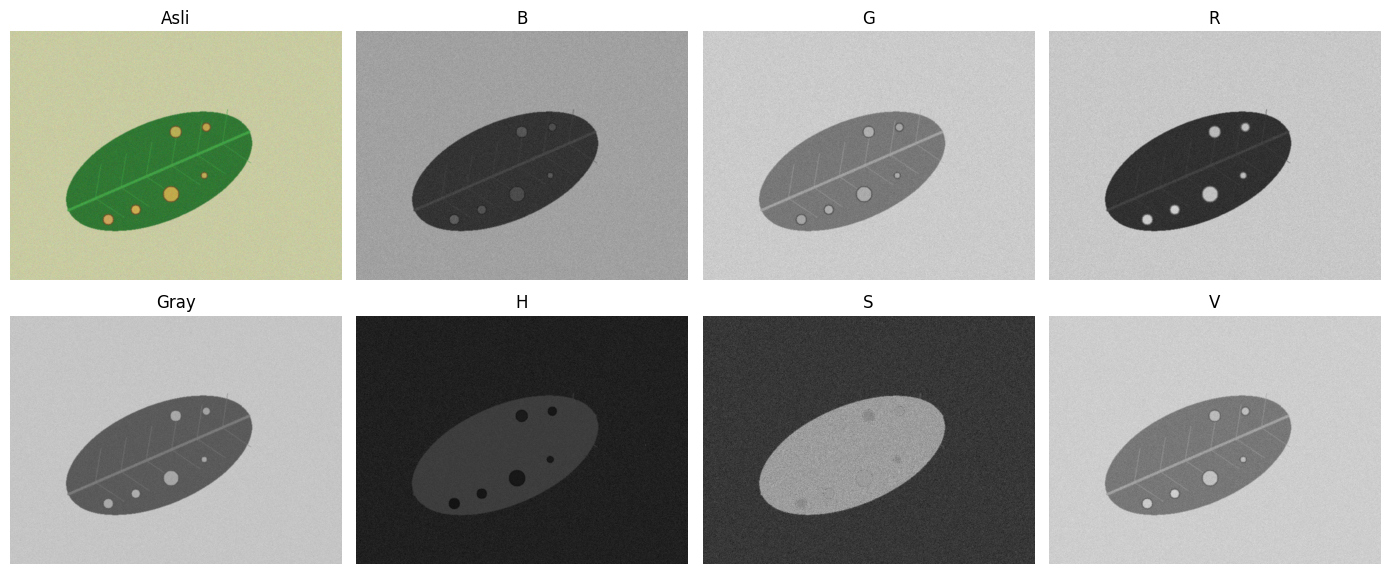

In [9]:
# Kode 2.1 Pemisahan kanal dan Kontras Bercak
from utils_cv import kontras_bercak

nama = "teh_041.png"                 # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [10]:
# Kode 2.2 Sampling dan kuantisasi
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md,
mb):.2f}")

# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=6.26
fx=0.2: ukuran (96, 128), KB=4.84
fx=0.1: ukuran (48, 64), KB=2.85
fx=0.05: ukuran (24, 32), KB=1.03
k=1: 2 level, KB=8.92
k=2: 3 level, KB=8.92
k=3: 5 level, KB=4.23
k=4: 10 level, KB=5.62
k=8: 148 level, KB=6.15


In [13]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b, "G": g, "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h, "S": s, "V": v
    }

label = pd.read_csv("../data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)

print(tabel_kb)

tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.36  0.77   5.41  2.11  4.29  0.63  1.55
gelap           1.42  1.31  10.86  4.59  6.49  0.76  3.36
kontras_rendah  0.65  0.27   3.19  1.72  1.44  0.12  1.15
normal          1.94  1.38   9.95  4.88  7.41  0.78  3.03
terang          2.99  0.84   8.55  4.51  7.10  1.51  2.32
